In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# Khởi tạo tham số
n_samples = 100
random_state = 170
center_points = 2  # Dữ liệu gốc chỉ có 2 tâm/cụm

# Sinh dữ liệu ngẫu nhiên theo phân phối Gauss
X, y = make_blobs(
    n_samples=n_samples, 
    random_state=random_state, 
    centers=center_points, 
    cluster_std=0.6
)

print("Kích thước X:", X.shape)
print("5 điểm dữ liệu đầu tiên:\n", X[:5])

Kích thước X: (100, 2)
5 điểm dữ liệu đầu tiên:
 [[-8.87090181 -6.2923396 ]
 [-5.68131011  0.92989934]
 [-4.48237839 -0.2011274 ]
 [-9.70586418 -5.3021706 ]
 [-8.77808596 -5.67185751]]


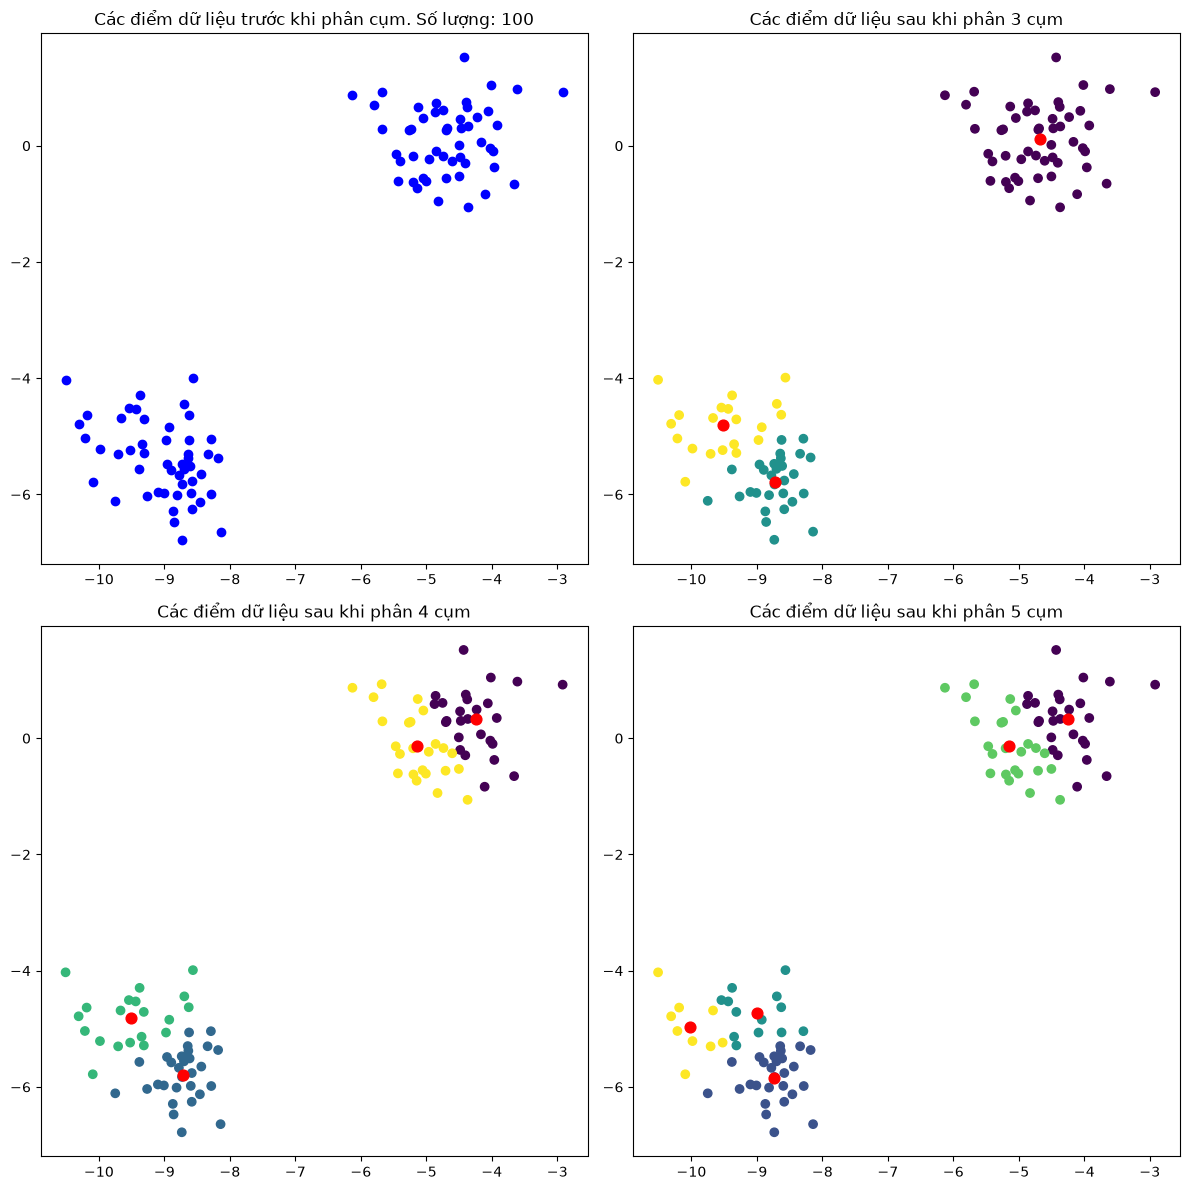

In [2]:
plt.figure(figsize=(12, 12))

# 1. Dữ liệu ban đầu trước khi phân cụm
plt.subplot(221)
plt.scatter(X[:, 0], X[:, 1], c='blue')
plt.title(f"Các điểm dữ liệu trước khi phân cụm. Số lượng: {n_samples}")

# 2. Huấn luyện với k = 3
kmeans_3 = KMeans(n_clusters=3, random_state=random_state)
kmeans_3.fit(X)
y_pred_3 = kmeans_3.predict(X)
centers_3 = kmeans_3.cluster_centers_

plt.subplot(222)
plt.scatter(X[:, 0], X[:, 1], c=y_pred_3, cmap='viridis')
plt.scatter(centers_3[:, 0], centers_3[:, 1], c='red', s=60, marker='o')
plt.title("Các điểm dữ liệu sau khi phân 3 cụm")

# 3. Huấn luyện với k = 4
kmeans_4 = KMeans(n_clusters=4, random_state=random_state)
kmeans_4.fit(X)
y_pred_4 = kmeans_4.predict(X)
centers_4 = kmeans_4.cluster_centers_

plt.subplot(223)
plt.scatter(X[:, 0], X[:, 1], c=y_pred_4, cmap='viridis')
plt.scatter(centers_4[:, 0], centers_4[:, 1], c='red', s=60, marker='o')
plt.title("Các điểm dữ liệu sau khi phân 4 cụm")

# 4. Huấn luyện với k = 5
kmeans_5 = KMeans(n_clusters=5, random_state=random_state)
kmeans_5.fit(X)
y_pred_5 = kmeans_5.predict(X)
centers_5 = kmeans_5.cluster_centers_

plt.subplot(224)
plt.scatter(X[:, 0], X[:, 1], c=y_pred_5, cmap='viridis')
plt.scatter(centers_5[:, 0], centers_5[:, 1], c='red', s=60, marker='o')
plt.title("Các điểm dữ liệu sau khi phân 5 cụm")

plt.tight_layout()
plt.show()

In [3]:
import os
from skimage import io
import matplotlib.image as image

path_img = 'bird_small.png'
img = io.imread(path_img)

# Lưu lại shape ban đầu (128, 128, 3)
img_shape = img.shape

# Chuẩn hóa về [0, 1] và reshape thành mảng 2 chiều (16384, 3)
data_img = (img / 255.0).reshape(-1, img_shape[2])

print("Kích thước ma trận ảnh gốc:", img_shape)
print("Kích thước sau khi reshape:", data_img.shape)

Kích thước ma trận ảnh gốc: (128, 128, 3)
Kích thước sau khi reshape: (16384, 3)


In [4]:
# Thiết lập k < 5 (chọn k = 3)
n_color = 3
kmeans_img = KMeans(n_clusters=n_color, random_state=42)
kmeans_img.fit(data_img)

# In thông tin tâm cụm (3 màu đại diện)
print("Tọa độ RGB của các tâm cụm (n_clusters, 3):\n", kmeans_img.cluster_centers_)

# Thay thế từng điểm ảnh bằng giá trị màu của tâm cụm tương ứng
compressed_data = kmeans_img.cluster_centers_[kmeans_img.labels_]

# Reshape mảng 2D trở lại kích thước ảnh ban đầu (128, 128, 3)
img_compressed = np.reshape(compressed_data, img_shape)

# Lưu ảnh đã nén ra đĩa
image.imsave('img_compressed_k3.png', img_compressed)

Tọa độ RGB của các tâm cụm (n_clusters, 3):
 [[0.62381675 0.49753051 0.3493971 ]
 [0.88342881 0.79344697 0.63247015]
 [0.14980169 0.14549728 0.13407215]]


Kích thước ảnh gốc: 33031 bytes
Kích thước ảnh nén (k=3): 2757 bytes


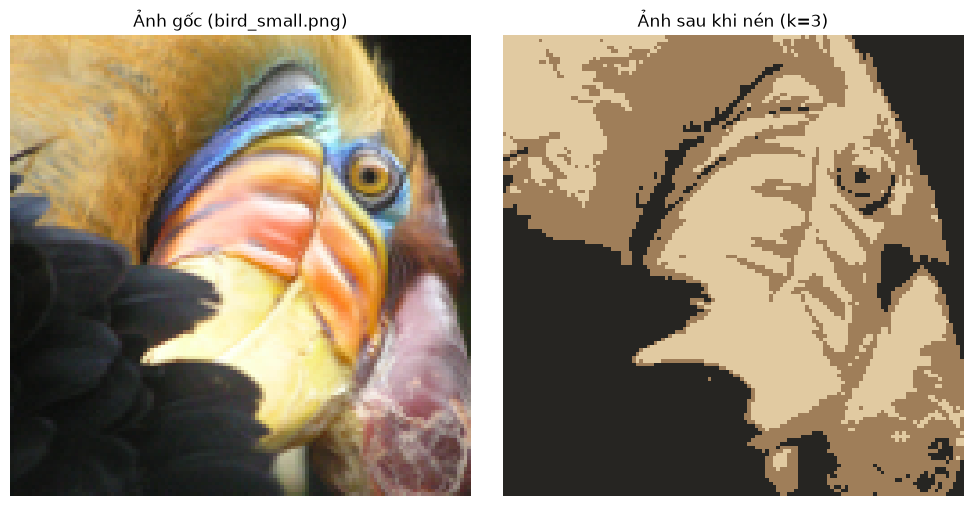

In [5]:
# So sánh dung lượng file
size_orig = os.path.getsize(path_img)
size_comp = os.path.getsize('img_compressed_k3.png')

print(f"Kích thước ảnh gốc: {size_orig} bytes")
print(f"Kích thước ảnh nén (k=3): {size_comp} bytes")

# Hiển thị trực quan ảnh gốc và ảnh sau khi nén cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img)
axes[0].set_title("Ảnh gốc (bird_small.png)")
axes[0].axis('off')

axes[1].imshow(img_compressed)
axes[1].set_title(f"Ảnh sau khi nén (k={n_color})")
axes[1].axis('off')

plt.tight_layout()
plt.show()